# Four-method bird detection demonstration
**Group 104 | M1 RF · M2 YOLO11s · M3 Faster R-CNN · M4 P2 + DySample**

Run cells from top to bottom. This notebook calls the current repository's `project.py` in isolated subprocesses, sequentially. It does not train models or download assets. It is a standalone demonstration file, but requires this repository, its dependencies, the dataset and compatible trained checkpoints.

The default demonstration uses three validation images. Switch to the full validation set with `FULL_VALIDATION=True`. Every figure and metric is generated by executing the current inference and evaluation commands; historical predictions are not substituted. Saved outputs below come from the verified demonstration run and remain visible before rerunning. Rerunning generates a new timestamped output folder. For the assessed video, record the actual execution and explain the results with your webcam visible.

In [1]:
from pathlib import Path
import sys, os, json, csv, subprocess, time, shutil, hashlib, random
from datetime import datetime, timezone
from IPython.display import display, Markdown
from PIL import Image, ImageDraw

# Run with a kernel containing the project dependencies. Change these paths on another PC.
REPO_HINT = Path(r"D:\Cursor\COMP-9517-26T3-Goup-Project")
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents, REPO_HINT] if (p / "project.py").is_file()), None)
assert REPO is not None, "Set REPO_HINT to the project folder."
DATASET = REPO / "Yolo Improeved/work/beach-bird/Beach Bird Detection Dataset v1.0"
RUN = REPO / "runs/5090d_batch8_seed42_20261117"
PYTHON = Path(sys.executable)  # Select the existing project .venv kernel; no automatic installation.
FULL_VALIDATION = False
IMAGE_IDS = ["beach_bird_1371", "beach_bird_1374", "beach_bird_1658"]
SEED = 42
DEVICE = "cuda:0"  # Use "cpu" if CUDA is unavailable (much slower).
random.seed(SEED)
METHODS = {"m1": "Random Forest", "m2": "YOLO11s baseline", "m3": "Faster R-CNN", "m4": "YOLO11s + P2 + DySample"}
WEIGHTS = {m: RUN / m / ("models/rf_final.joblib" if m == "m1" else "best.pt") for m in METHODS}
STAMP = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT = REPO / "demo_outputs" / ("four_methods_" + STAMP)
print("Repository:", REPO, "\nInterpreter:", PYTHON, "\nOutputs:", OUT)


Repository: D:\Cursor\COMP-9517-26T3-Goup-Project 
Interpreter: D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe 
Outputs: D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298


## 1. Preflight and provenance
No weights or dependencies are downloaded. Missing inputs stop execution with a clear error. The four checkpoints come from the same matched seed-42 experiment; M1 is a classical RF model and has no neural epoch schedule.

In [2]:
import torch, torchvision, ultralytics, joblib, cv2, numpy, sklearn, pycocotools
assert ultralytics.__version__ == "8.3.221", "Use the pinned project environment."
assert DEVICE == "cpu" or torch.cuda.is_available(), "CUDA unavailable: change DEVICE to cpu or select the correct kernel."
assert (DATASET / "images/val").is_dir(), f"Dataset not found: {DATASET}"
for method, path in WEIGHTS.items():
    assert path.is_file(), f"Missing {method} checkpoint: {path}"
OUT.mkdir(parents=True, exist_ok=False)
ENV = os.environ.copy()
ENV.update(PYTHONIOENCODING="utf-8", PYTHONUNBUFFERED="1", PYTHONHASHSEED=str(SEED))
provenance = dict(created_utc=datetime.now(timezone.utc).isoformat(), seed=SEED,
    git_commit=subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip(),
    working_tree_status=subprocess.check_output(["git", "status", "--porcelain"], cwd=REPO, text=True),
    python=str(PYTHON), torch=torch.__version__, torchvision=torchvision.__version__,
    ultralytics=ultralytics.__version__, device=DEVICE,
    gpu=torch.cuda.get_device_name(0) if DEVICE.startswith("cuda") else None,
    checkpoints={m: {"path":str(p), "sha256":hashlib.file_digest(p.open("rb"), "sha256").hexdigest()} for m,p in WEIGHTS.items()})
print(json.dumps(provenance, indent=2))


{
  "created_utc": "2026-11-18T22:01:49.348550+00:00",
  "seed": 42,
  "git_commit": "cacf9873a458aabd5e4a3edf67be486ffaddbe82",
  "working_tree_status": " M .gitignore\n M \"reports/COMP9517_Group104_\\344\\270\\255\\346\\226\\207\\351\\241\\271\\347\\233\\256\\346\\212\\245\\345\\221\\212.docx\"\n M \"reports/COMP9517_Group104_\\344\\270\\255\\346\\226\\207\\351\\241\\271\\347\\233\\256\\346\\212\\245\\345\\221\\212.pdf\"\n M tools/reporting/analyze.py\n M tools/reporting/build_report.py\n M tools/reporting/build_robustness_report.py\n M tools/reporting/build_supplement_report.py\n?? notebooks/\n?? reports/COMP9517_Group104_English_Report_Draft_v1.docx\n?? reports/COMP9517_Group104_English_Report_Draft_v1.pdf\n?? reports/COMP9517_Group104_English_Report_RawLoss_v2.docx\n?? reports/COMP9517_Group104_English_Report_RawLoss_v2.pdf\n?? \"reports/COMP9517_Group104_\\344\\270\\255\\346\\226\\207\\346\\212\\245\\345\\221\\212_\\345\\216\\237\\345\\247\\213Loss\\347\\211\\210.docx\"\n?? \"re

## 2. Select the common validation inputs
Quick mode copies exactly three image/label pairs into a new demo-only folder. Original data is untouched. These examples are qualitative illustrations, not a representative accuracy estimate. Set `FULL_VALIDATION=True` above for all 291 validation images. The test set is not used for demo tuning.

In [3]:
if FULL_VALIDATION:
    DEMO_DATA = DATASET
else:
    DEMO_DATA = OUT / "subset"
    for folder in ["images/val", "labels/val"]:
        (DEMO_DATA / folder).mkdir(parents=True)
    for stem in IMAGE_IDS:
        matches = [p for p in (DATASET / "images/val").glob(stem + ".*") if p.suffix.lower() in {".jpg", ".png", ".jpeg"}]
        assert len(matches) == 1, f"Image missing or ambiguous: {stem}"
        label = DATASET / "labels/val" / (stem + ".txt")
        assert label.is_file(), f"Label missing: {label}"
        shutil.copy2(matches[0], DEMO_DATA / "images/val" / matches[0].name)
        shutil.copy2(label, DEMO_DATA / "labels/val" / label.name)
provenance.update(full_validation=FULL_VALIDATION, dataset=str(DATASET), inference_root=str(DEMO_DATA), image_ids=IMAGE_IDS)
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print("Evaluation scope:", "full validation" if FULL_VALIDATION else "DEMO SUBSET ONLY", "\nRoot:", DEMO_DATA)


Evaluation scope: DEMO SUBSET ONLY 
Root: D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset


## 3. Shared execution and visualization
Each subprocess must finish successfully before the next starts. Commands and complete logs are saved. Boxes are in original-image pixels. Green: matched predictions; red: unmatched predictions; cyan: missed annotations, using score ≥ 0.25 and greedy one-to-one IoU ≥ 0.5 matching. This overlay threshold does not filter the CSV used for AP calculation.

In [4]:
records = {}
def run_cli(arguments, log_path):
    cmd = [str(PYTHON), "-u", str(REPO / "project.py"), *map(str, arguments)]
    print(subprocess.list2cmdline(cmd), flush=True)
    start = time.perf_counter()
    with log_path.open("w", encoding="utf-8") as log:
        log.write(subprocess.list2cmdline(cmd) + "\n")
        with subprocess.Popen(cmd, cwd=REPO, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                              text=True, encoding="utf-8", errors="replace") as process:
            try:
                for line in process.stdout:
                    print(line, end="", flush=True); log.write(line); log.flush()
                status = process.wait()
            except BaseException:
                process.terminate(); process.wait(); raise
    if status:
        raise RuntimeError(f"Command failed ({status}); see {log_path}")
    return time.perf_counter() - start

def overlay(method, stem, rows):
    paths = list((DEMO_DATA / "images/val").glob(stem + ".*"))
    picture = Image.open(paths[0]).convert("RGB"); w,h = picture.size
    boxes = []
    for line in (DEMO_DATA / "labels/val" / (stem + ".txt")).read_text().splitlines():
        _,xc,yc,bw,bh = map(float, line.split()); boxes.append(((xc-bw/2)*w,(yc-bh/2)*h,bw*w,bh*h))
    def iou(a,b):
        ax,ay,aw,ah=a; bx,by,bw,bh=b
        inter=max(0,min(ax+aw,bx+bw)-max(ax,bx))*max(0,min(ay+ah,by+bh)-max(ay,by))
        return inter / max(aw*ah+bw*bh-inter, 1e-9)
    canvas=Image.new("RGB",(w,h+64),"white"); canvas.paste(picture,(0,64)); draw=ImageDraw.Draw(canvas)
    used=set(); fp=0
    for r in sorted((r for r in rows if r["image_id"]==stem and float(r["score"])>=.25),key=lambda r:-float(r["score"])):
        b=tuple(float(r[k]) for k in ["x","y","width","height"])
        matches=[j for j,g in enumerate(boxes) if j not in used and iou(b,g)>=.5]
        if matches: used.add(max(matches,key=lambda j:iou(b,boxes[j]))); colour="#16a34a"
        else: fp+=1; colour="#dc2626"
        x,y,bw,bh=b; draw.rectangle((x,y+64,x+bw,y+bh+64),outline=colour,width=2)
    for j,(x,y,bw,bh) in enumerate(boxes):
        if j not in used: draw.rectangle((x,y+64,x+bw,y+bh+64),outline="#06b6d4",width=2)
    draw.text((8,5),f"{method.upper()}: {METHODS[method]}",fill="black")
    draw.text((8,24),f"{stem} | GT={len(boxes)} TP={len(used)} FP={fp} FN={len(boxes)-len(used)}",fill="black")
    draw.text((8,43),"Green=TP  Red=FP  Cyan=FN | score>=0.25, IoU>=0.5",fill="black")
    canvas.save(OUT / method / (stem + "_overlay.png"))
    return canvas

def demonstrate(method):
    folder=OUT / method; folder.mkdir(exist_ok=True)
    preds=folder / "preds_val.csv"; metrics=folder / "val_metrics.json"
    infer_seconds=run_cli(["infer", "--method",method,"--root",DEMO_DATA,"--run",RUN,"--weights",WEIGHTS[method],
                          "--split","val","--out",preds,"--device",DEVICE,"--workers","1"], folder / "infer.log")
    run_cli(["evaluate","--method",method,"--root",DEMO_DATA,"--run",RUN,"--split","val", "--preds",preds,"--out",metrics], folder / "evaluate.log")
    values=json.loads(metrics.read_text(encoding="utf-8"))
    with preds.open(newline="",encoding="utf-8") as file: rows=list(csv.DictReader(file))
    records[method] = dict(metrics=values, subprocess_wall_seconds=infer_seconds, prediction_rows=len(rows))
    print(f"Exported {len(rows)} prediction rows. Wall time including startup/loading: {infer_seconds:.2f}s (not benchmark latency).")
    display(Markdown(" | ".join(f"**{k}** {values[k]*100:.2f}%" for k in ["AP50","AP50:95","AP-small","precision","recall","F1"] if values.get(k) is not None)))
    for stem in IMAGE_IDS:
        if list((DEMO_DATA / "images/val").glob(stem + ".*")): display(overlay(method,stem,rows))
    (OUT / "results.json").write_text(json.dumps(records,indent=2),encoding="utf-8")


## M1 — Handcrafted features + Random Forest; CPU sliding-window detector.
Execute this cell and inspect the outputs before moving to the next method.

"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py infer --method m1 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --weights D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117\m1\models\rf_final.joblib --split val --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m1\preds_val.csv --device cuda:0 --workers 1


Starting: infer.py


repeat 1/1: 59.7s total, 19.91s/img


900 detections on 3 images -> D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m1\preds_val.csv (62s wall)


"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py evaluate --method m1 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --split val --preds D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m1\preds_val.csv --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m1\val_metrics.json


Starting: evaluate.py


... (55 outputs left out)

  }


}


Exported 900 prediction rows. Wall time including startup/loading: 63.17s (not benchmark latency).


**AP50** 14.88% | **AP50:95** 4.22% | **AP-small** 1.74% | **precision** 6.00% | **recall** 46.55% | **F1** 10.63%

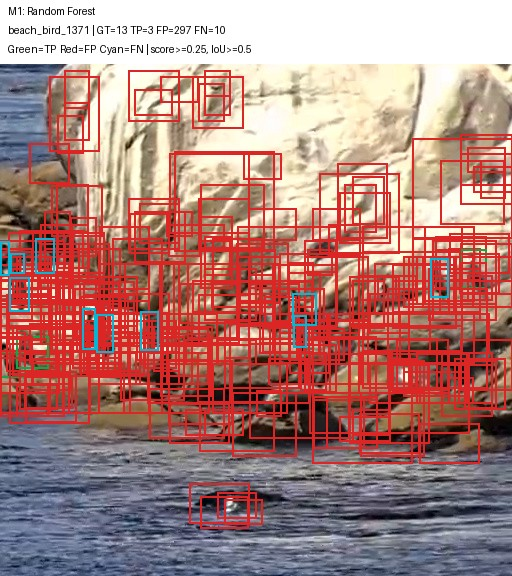

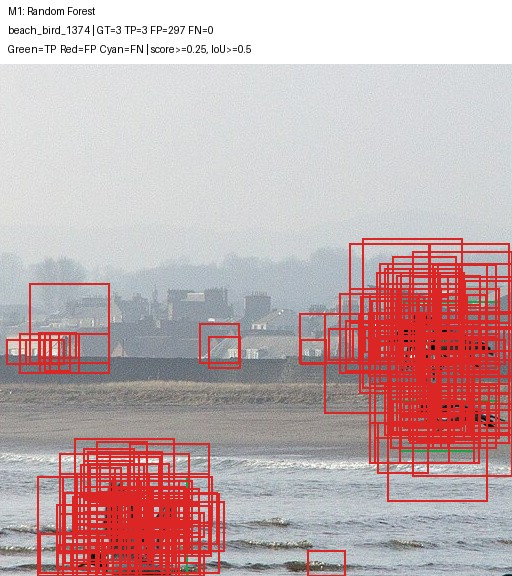

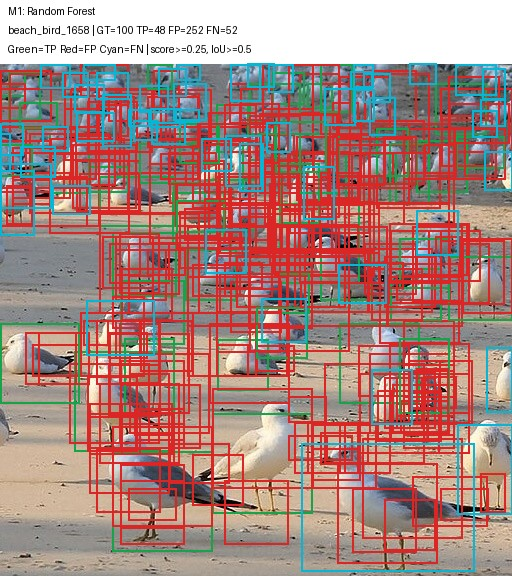

In [5]:
demonstrate("m1")

## M2 — Standard YOLO11s baseline, without the P2/DySample modification.
Execute this cell and inspect the outputs before moving to the next method.

"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py infer --method m2 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --weights D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117\m2\best.pt --split val --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m2\preds_val.csv --device cuda:0 --workers 1


Starting: infer.py


Overriding model.yaml nc=80 with nc=1


Wrote 570 predictions to D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m2\preds_val.csv


"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py evaluate --method m2 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --split val --preds D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m2\preds_val.csv --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m2\val_metrics.json


Starting: evaluate.py


... (55 outputs left out)

  }


}


Exported 570 prediction rows. Wall time including startup/loading: 8.01s (not benchmark latency).


**AP50** 88.21% | **AP50:95** 37.78% | **AP-small** 28.25% | **precision** 80.65% | **recall** 86.21% | **F1** 83.33%

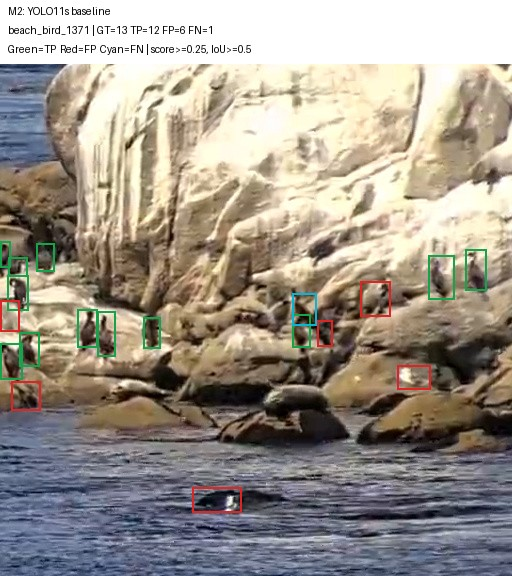

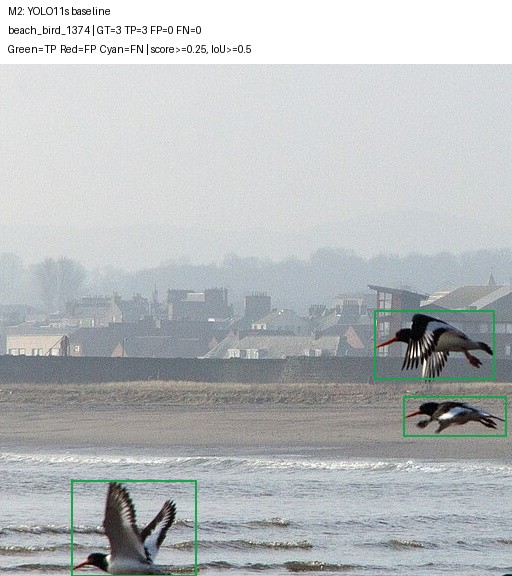

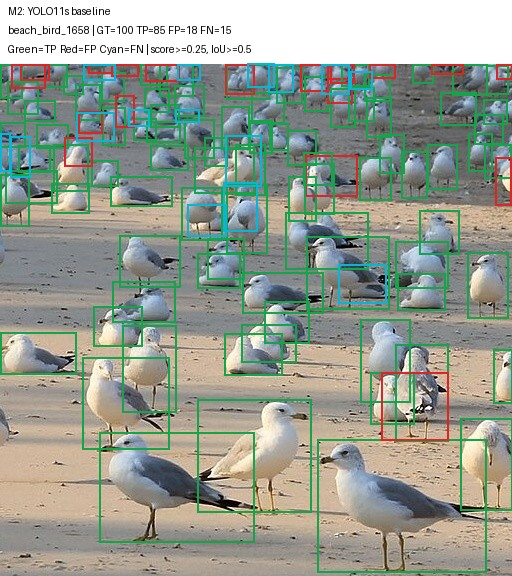

In [6]:
demonstrate("m2")

## M3 — Faster R-CNN with ResNet-50 FPN V2 backbone; matched-run checkpoint.
Execute this cell and inspect the outputs before moving to the next method.

"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py infer --method m3 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --weights D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117\m3\best.pt --split val --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m3\preds_val.csv --device cuda:0 --workers 1


Starting: pipeline.py


C:\Users\hrole\AppData\Roaming\Python\Python313\site-packages\torchvision\models\detection\backbone_utils.py:162: UserWarning: Changing trainable_backbone_layers has no effect if neither pretrained nor pretrained_backbone have been set to True, falling back to trainable_backbone_layers=5 so that all layers are trainable


  warnings.warn(


"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py evaluate --method m3 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --split val --preds D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m3\preds_val.csv --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m3\val_metrics.json


Starting: evaluate.py


... (55 outputs left out)

  }


}


Exported 387 prediction rows. Wall time including startup/loading: 7.27s (not benchmark latency).


**AP50** 83.74% | **AP50:95** 36.28% | **AP-small** 29.99% | **precision** 79.67% | **recall** 84.48% | **F1** 82.01%

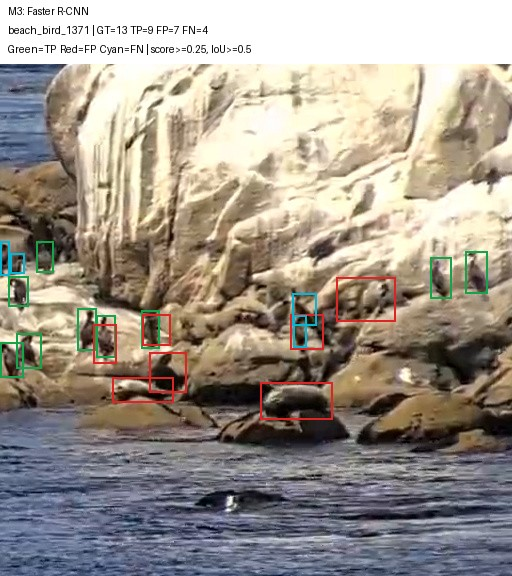

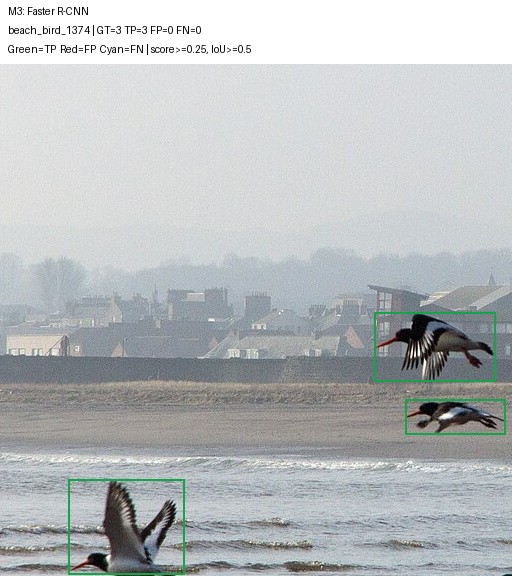

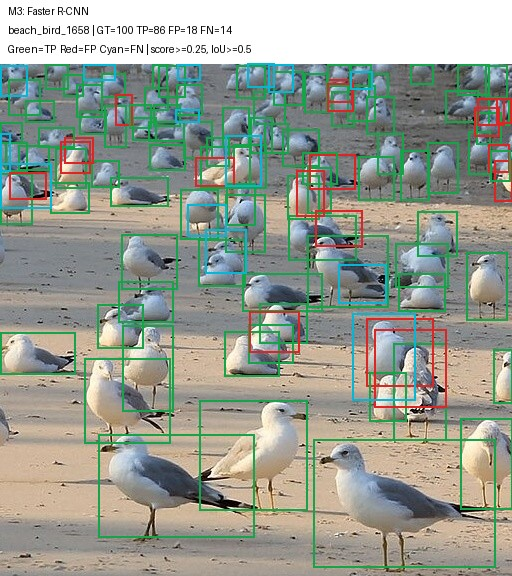

In [7]:
demonstrate("m3")

## M4 — Improved YOLO11s with P2 detection head and DySample.
Execute this cell and inspect the outputs before moving to the next method.

"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py infer --method m4 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --weights D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117\m4\best.pt --split val --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m4\preds_val.csv --device cuda:0 --workers 1


Starting: infer.py


C:\Users\hrole\AppData\Roaming\Python\Python313\site-packages\torch\functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4384.)


  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Wrote 545 predictions to D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m4\preds_val.csv


"D:\Cursor\COMP-9517-26T3-Goup-Project\Yolo Improeved\.venv\Scripts\python.exe" -u D:\Cursor\COMP-9517-26T3-Goup-Project\project.py evaluate --method m4 --root D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\subset --run D:\Cursor\COMP-9517-26T3-Goup-Project\runs\5090d_batch8_seed42_20261117 --split val --preds D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m4\preds_val.csv --out D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298\m4\val_metrics.json


... (56 outputs left out)

  }


}


Exported 545 prediction rows. Wall time including startup/loading: 7.27s (not benchmark latency).


**AP50** 83.59% | **AP50:95** 36.85% | **AP-small** 28.46% | **precision** 74.80% | **recall** 81.90% | **F1** 78.19%

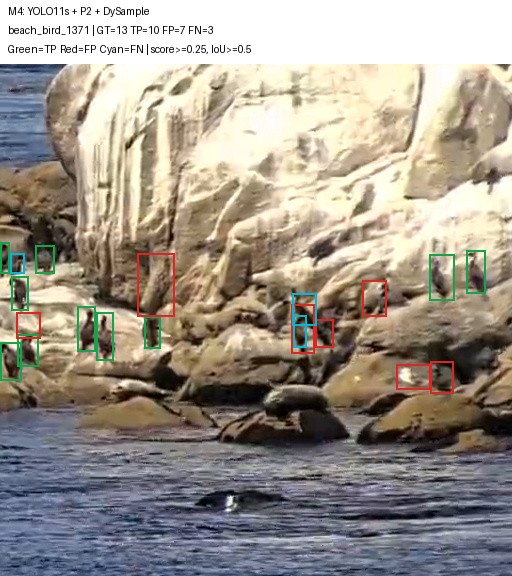

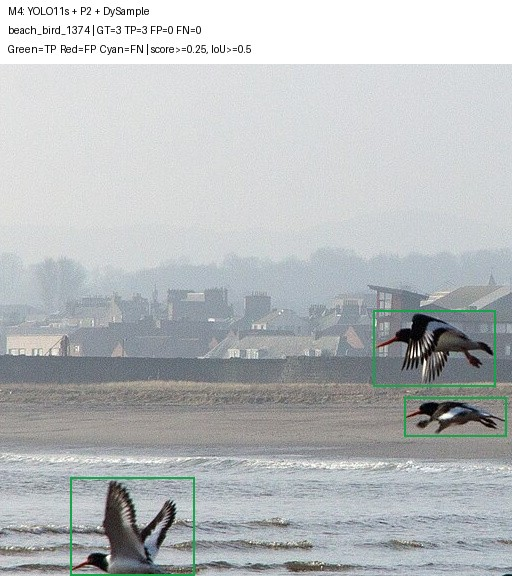

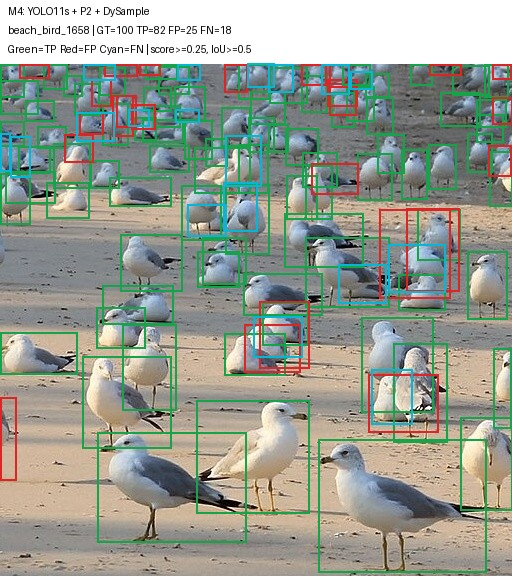

In [8]:
demonstrate("m4")

## 4. Side-by-side results and scope
All metrics below are recomputed on the same current inputs by the shared evaluator (COCO maxDets=300). AP uses the exported low-threshold predictions; precision/recall/F1 use score ≥ 0.25 and IoU ≥ 0.5. Demo wall times include startup and checkpoint loading and must not be presented as warmed-up throughput benchmarks. One seed is used; no uncertainty claim is made.

### DEMO SUBSET ONLY — NOT THE REPORT BENCHMARK
| Method | AP50 | AP50:95 | AP-small | Precision | Recall | F1 | Process wall s |
|---|---:|---:|---:|---:|---:|---:|---:|
| M1 Random Forest | 14.88% | 4.22% | 1.74% | 6.00% | 46.55% | 10.63% | 63.17 |
| M2 YOLO11s baseline | 88.21% | 37.78% | 28.25% | 80.65% | 86.21% | 83.33% | 8.01 |
| M3 Faster R-CNN | 83.74% | 36.28% | 29.99% | 79.67% | 84.48% | 82.01% | 7.27 |
| M4 YOLO11s + P2 + DySample | 83.59% | 36.85% | 28.46% | 74.80% | 81.90% | 78.19% | 7.27 |

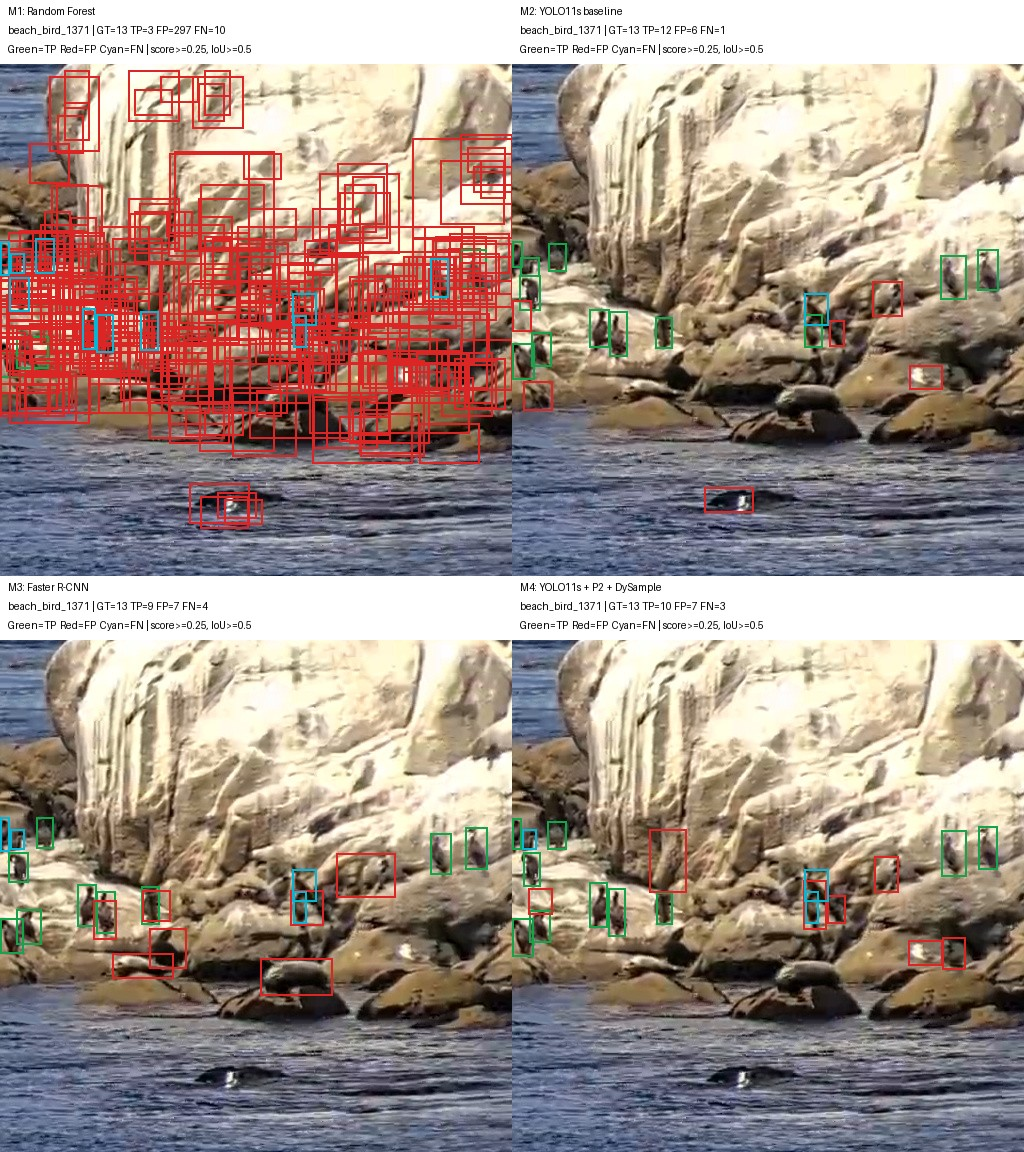

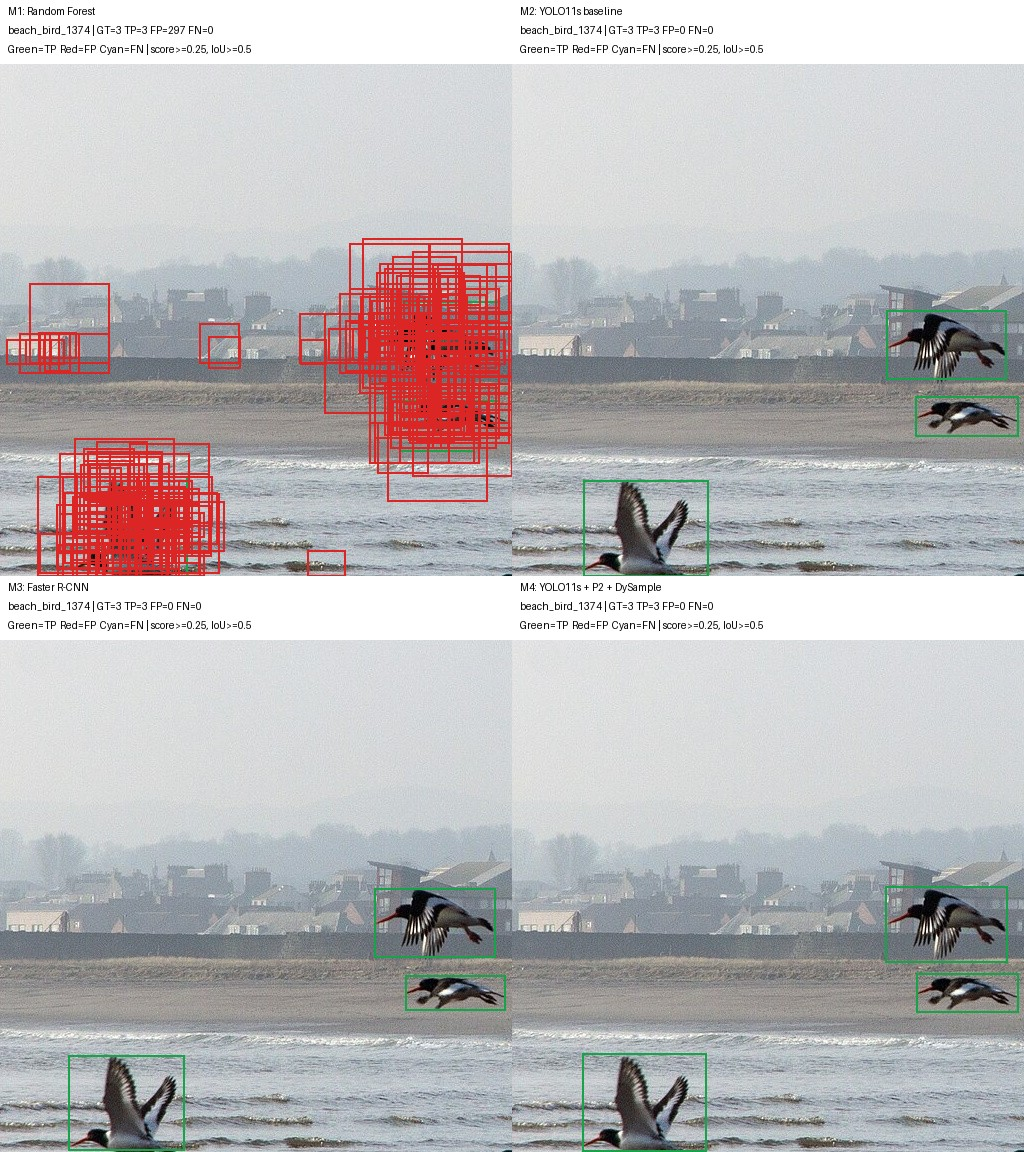

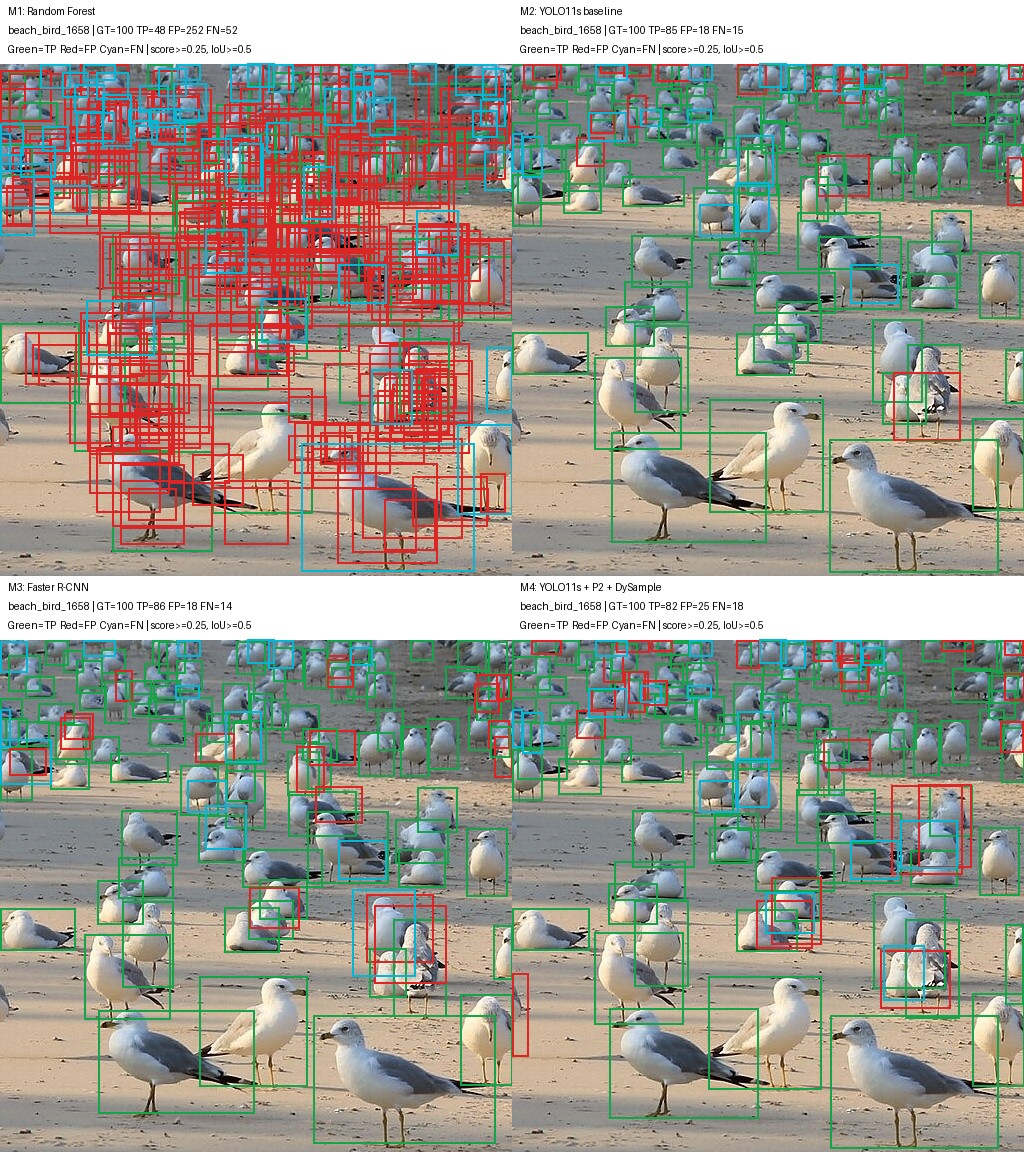

Saved predictions, metrics, overlays, logs and provenance to: D:\Cursor\COMP-9517-26T3-Goup-Project\demo_outputs\four_methods_20261119_090143_651298


In [9]:
assert set(records) == set(METHODS), "Run all four method cells first."
scope = "FULL VALIDATION" if FULL_VALIDATION else "DEMO SUBSET ONLY — NOT THE REPORT BENCHMARK"
lines=[f"### {scope}", "| Method | AP50 | AP50:95 | AP-small | Precision | Recall | F1 | Process wall s |", "|---|---:|---:|---:|---:|---:|---:|---:|"]
for method in METHODS:
    r=records[method]; values=r["metrics"]
    percentages=[f"{100*values[k]:.2f}%" if values.get(k) is not None else "N/A" for k in ["AP50","AP50:95","AP-small","precision","recall","F1"]]
    lines.append("| " + " | ".join([method.upper()+" "+METHODS[method], *percentages, f"{r['subprocess_wall_seconds']:.2f}"]) + " |")
display(Markdown("\n".join(lines)))
(OUT / "comparison.md").write_text("\n".join(lines),encoding="utf-8")
# A single contact sheet per image makes the four methods easy to compare on screen.
for stem in IMAGE_IDS:
    pictures=[Image.open(OUT / m / (stem+"_overlay.png")).convert("RGB") for m in METHODS]
    w=max(p.width for p in pictures); h=max(p.height for p in pictures)
    sheet=Image.new("RGB",(w*2,h*2),"white")
    for i,picture in enumerate(pictures): sheet.paste(picture,((i%2)*w,(i//2)*h))
    sheet.save(OUT / (stem+"_four_methods.png")); display(sheet)
print("Saved predictions, metrics, overlays, logs and provenance to:", OUT)


## Recording checklist
1. Show the four method names and input scope; do not claim three images establish general accuracy.
2. Show a real inference command and its terminal output, then the corresponding overlay and evaluation output. Other method runs can be edited for time.
3. Use a side-by-side image to explain one success and one failure; distinguish false positives from missed birds.
4. Use the report's complete held-out results for final comparisons, keeping validation diagnostics and test results separate. No training, parameter selection or checkpoint replacement is performed here.
5. Keep the full group video within 10 minutes, with about 2 minutes of actual software demonstration. All speakers must introduce their name and appear on camera.

**Portability:** copy this `.ipynb` into a clone of the project and update the first cell's dataset/run paths; install the common project requirements and select a compatible Python kernel. Weights and dataset are separate local prerequisites and are not embedded in this notebook.